# Historical confused-student experiment
This notebook preserves the supplied experiment and its saved outputs. Outputs have **not** been recomputed for this repository. Only local setup cells were adapted.
**Read [AI and data review](../docs/AI_AND_DATA.md) before interpreting results.** Known issues include preprocessing before splitting, 11 empty sequence slots, participant overlap, reuse of validation for evaluation, and a recurrent axis of length one. The saved 75% result is not a validated claim about this headset or classroom performance.
Start Jupyter from this notebooks directory; obtain the public CSV as described in [data instructions](../data/README.md).


In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from tensorflow.keras.layers import Input, Conv2D, Dense, Flatten, Dropout, BatchNormalization,LSTM,Bidirectional,MaxPooling2D,GlobalMaxPooling2D,TimeDistributed
from tensorflow.keras.models import Model, Sequential
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.utils import plot_model
from sklearn.metrics import confusion_matrix

In [ ]:
# Install the notebook requirements before starting Jupyter.


In [ ]:
# Local version: place the public dataset in ../data/public/.


In [ ]:
# Dataset download instructions are in ../data/README.md.


In [ ]:
file_path = '../data/public/EEG_data_college_students.csv'


In [21]:
 data = pd.read_csv(file_path)
data.head()

,SubjectID,VideoID,Attention,Mediation,Raw,Delta,Theta,Alpha1,Alpha2,Beta1,Beta2,Gamma1,Gamma2,predefinedlabel,user-definedlabeln
0,0.0,0.0,56.0,43.0,278.0,301963.0,90612.0,33735.0,23991.0,27946.0,45097.0,33228.0,8293.0,0.0,0.0
1,0.0,0.0,40.0,35.0,-50.0,73787.0,28083.0,1439.0,2240.0,2746.0,3687.0,5293.0,2740.0,0.0,0.0
2,0.0,0.0,47.0,48.0,101.0,758353.0,383745.0,201999.0,62107.0,36293.0,130536.0,57243.0,25354.0,0.0,0.0
3,0.0,0.0,47.0,57.0,-5.0,2012240.0,129350.0,61236.0,17084.0,11488.0,62462.0,49960.0,33932.0,0.0,0.0
4,0.0,0.0,44.0,53.0,-8.0,1005145.0,354328.0,37102.0,88881.0,45307.0,99603.0,44790.0,29749.0,0.0,0.0


In [22]:
demographic_data = pd.read_csv(file_path)
demographic_data = demographic_data.rename(columns = {'subject ID':'SubjectID'})
demographic_data

,SubjectID,VideoID,Attention,Mediation,Raw,Delta,Theta,Alpha1,Alpha2,Beta1,Beta2,Gamma1,Gamma2,predefinedlabel,user-definedlabeln
0,0.0,0.0,56.0,43.0,278.0,301963.0,90612.0,33735.0,23991.0,27946.0,45097.0,33228.0,8293.0,0.0,0.0
1,0.0,0.0,40.0,35.0,-50.0,73787.0,28083.0,1439.0,2240.0,2746.0,3687.0,5293.0,2740.0,0.0,0.0
2,0.0,0.0,47.0,48.0,101.0,758353.0,383745.0,201999.0,62107.0,36293.0,130536.0,57243.0,25354.0,0.0,0.0
3,0.0,0.0,47.0,57.0,-5.0,2012240.0,129350.0,61236.0,17084.0,11488.0,62462.0,49960.0,33932.0,0.0,0.0
4,0.0,0.0,44.0,53.0,-8.0,1005145.0,354328.0,37102.0,88881.0,45307.0,99603.0,44790.0,29749.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
12806,9.0,9.0,64.0,38.0,-39.0,127574.0,9951.0,709.0,21732.0,3872.0,39728.0,2598.0,960.0,1.0,0.0
12807,9.0,9.0,61.0,35.0,-275.0,323061.0,797464.0,153171.0,145805.0,39829.0,571280.0,36574.0,10010.0,1.0,0.0
12808,9.0,9.0,60.0,29.0,-426.0,680989.0,154296.0,40068.0,39122.0,10966.0,26975.0,20427.0,2024.0,1.0,0.0
12809,9.0,9.0,60.0,29.0,-84.0,366269.0,27346.0,11444.0,9932.0,1939.0,3283.0,12323.0,1764.0,1.0,0.0


In [23]:
unique_data = pd.DataFrame([data[c].value_counts().size for c in data.columns], index=data.columns, columns = ['count of unique values'])
unique_data

,count of unique values
SubjectID,10
VideoID,10
Attention,61
Mediation,61
Raw,1104
Delta,12280
Theta,12070
Alpha1,11140
Alpha2,10910
Beta1,10583


from matplotlib import pyplot as plt
unique_data['count of unique values'].plot(kind='hist', bins=20, title='count of unique values')
plt.gca().spines[['top', 'right',]].set_visible(False)

from matplotlib import pyplot as plt
unique_data['count of unique values'].plot(kind='line', figsize=(8, 4), title='count of unique values')
plt.gca().spines[['top', 'right']].set_visible(False)

Error: Runtime no longer has a reference to this dataframe, please re-run this cell and try again.


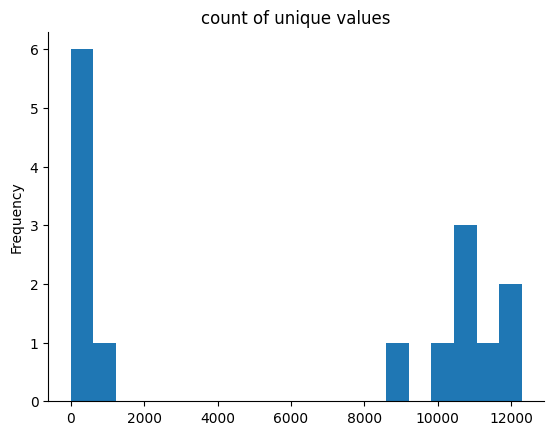

In [27]:
from matplotlib import pyplot as plt
unique_data['count of unique values'].plot(kind='hist', bins=20, title='count of unique values')
plt.gca().spines[['top', 'right',]].set_visible(False)

In [28]:
data.isnull().sum()

SubjectID             0
VideoID               0
Attention             0
Mediation             0
Raw                   0
Delta                 0
Theta                 0
Alpha1                0
Alpha2                0
Beta1                 0
Beta2                 0
Gamma1                0
Gamma2                0
predefinedlabel       0
user-definedlabeln    0
dtype: int64

In [29]:
data.describe()

,SubjectID,VideoID,Attention,Mediation,Raw,Delta,Theta,Alpha1,Alpha2,Beta1,Beta2,Gamma1,Gamma2,predefinedlabel,user-definedlabeln
count,12811.000000,12811.000000,12811.000000,12811.000000,12811.000000,1.281100e+04,1.281100e+04,1.281100e+04,1.281100e+04,1.281100e+04,1.281100e+04,1.281100e+04,1.281100e+04,12811.000000,12811.000000
mean,4.487394,4.390602,41.313871,47.182656,65.570760,6.057853e+05,1.680526e+05,4.138435e+04,3.318339e+04,2.431837e+04,3.814433e+04,2.959255e+04,1.441597e+04,0.479978,0.512606
std,2.865373,2.913232,23.152953,22.655976,597.921035,6.376236e+05,2.441346e+05,7.243082e+04,5.831410e+04,3.837968e+04,7.906606e+04,7.982637e+04,3.603523e+04,0.499618,0.499861
min,0.000000,0.000000,0.000000,0.000000,-2048.000000,4.480000e+02,1.700000e+01,2.000000e+00,2.000000e+00,3.000000e+00,2.000000e+00,1.000000e+00,2.000000e+00,0.000000,0.000000
25%,2.000000,2.000000,27.000000,37.000000,-14.000000,9.806400e+04,2.691750e+04,6.838000e+03,6.852000e+03,6.140000e+03,7.358500e+03,4.058000e+03,2.167500e+03,0.000000,0.000000
50%,4.000000,4.000000,43.000000,51.000000,35.000000,3.954870e+05,8.133100e+04,1.750000e+04,1.495900e+04,1.281800e+04,1.581000e+04,9.763000e+03,5.116000e+03,0.000000,1.000000
75%,7.000000,7.000000,57.000000,63.000000,90.000000,9.166230e+05,2.052760e+05,4.477950e+04,3.455050e+04,2.740600e+04,3.549400e+04,2.488800e+04,1.266950e+04,1.000000,1.000000
max,9.000000,9.000000,100.000000,100.000000,2047.000000,3.964663e+06,3.007802e+06,1.369955e+06,1.016913e+06,1.067778e+06,1.645369e+06,1.972506e+06,1.348117e+06,1.000000,1.000000


In [30]:
dataset = data.copy()
dataset = dataset[dataset['Attention'] > 0.0]
dataset = dataset[dataset['Mediation'] > 0.0]
dataset_all = dataset.copy()
dataset.drop(columns = ['SubjectID','VideoID','predefinedlabel'],inplace=True)


In [ ]:
print("After cleaning, the data has {} rows and {} columns.".format(dataset.shape[0],dataset.shape[1]))

After cleaning, the data has 11388 rows and 12 columns.


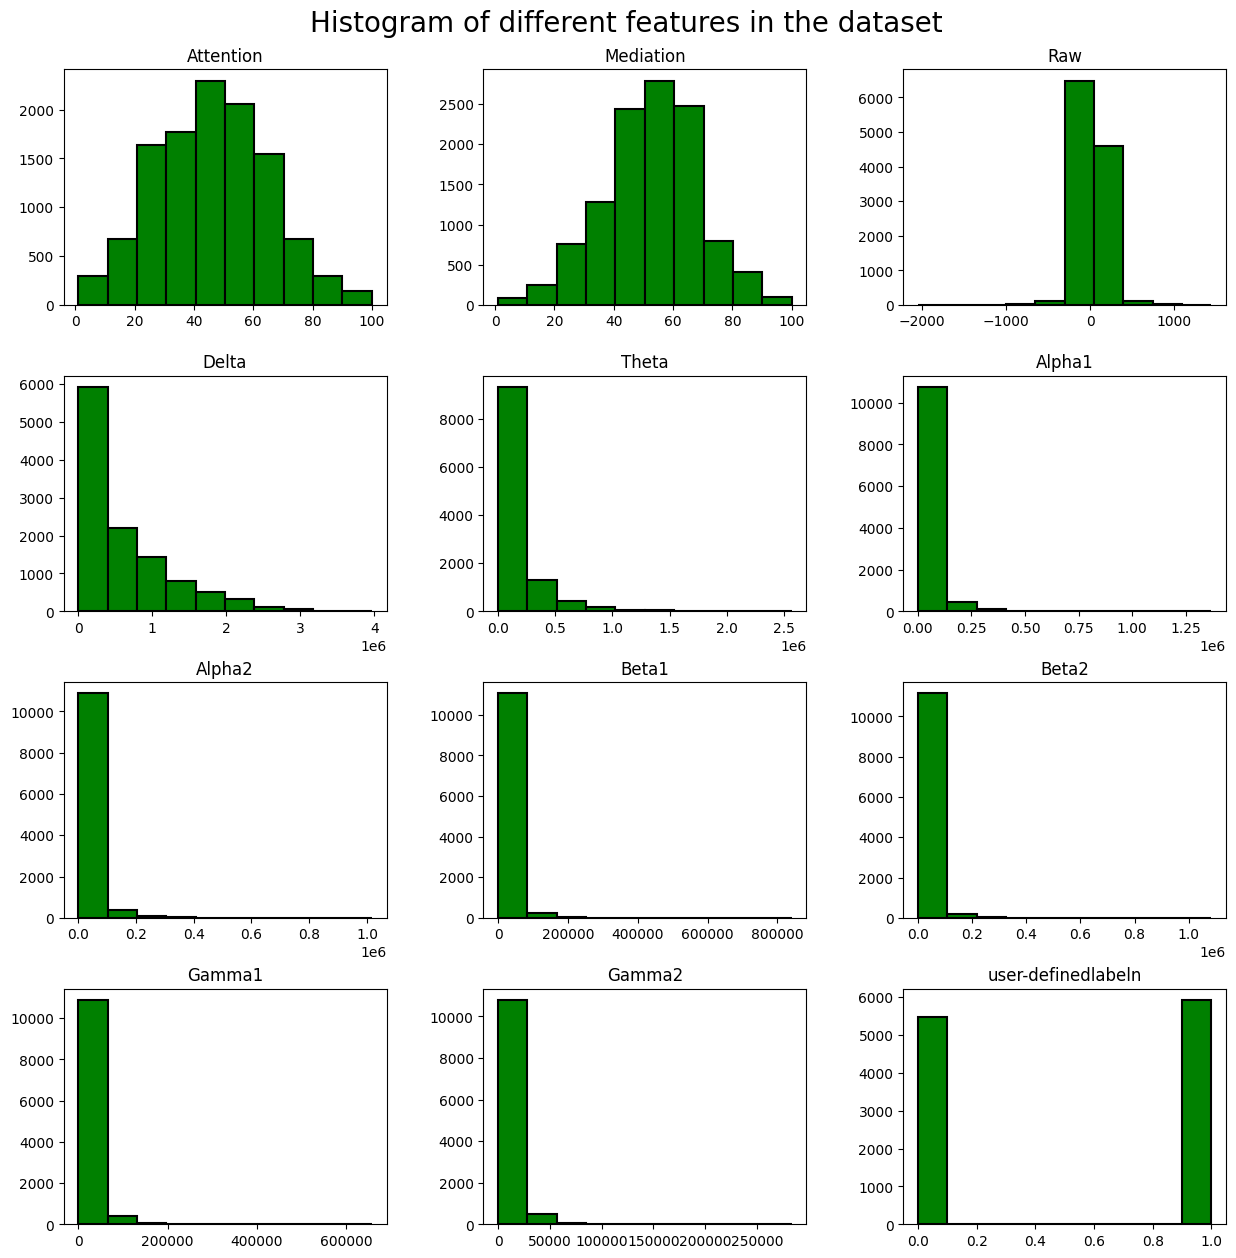

In [31]:
dataset.hist(figsize = (15,15), grid = False, color = "green", edgecolor = 'black',linewidth = 1.5 )
plt.suptitle('Histogram of different features in the dataset',fontsize = 20,y= 0.92)
plt.show()

array([[<Axes: title={'center': 'Delta'}>,
        <Axes: title={'center': 'Theta'}>,
        <Axes: title={'center': 'Alpha1'}>],
       [<Axes: title={'center': 'Alpha2'}>,
        <Axes: title={'center': 'Beta1'}>,
        <Axes: title={'center': 'Beta2'}>],
       [<Axes: title={'center': 'Gamma1'}>,
        <Axes: title={'center': 'Gamma2'}>, <Axes: >]], dtype=object)

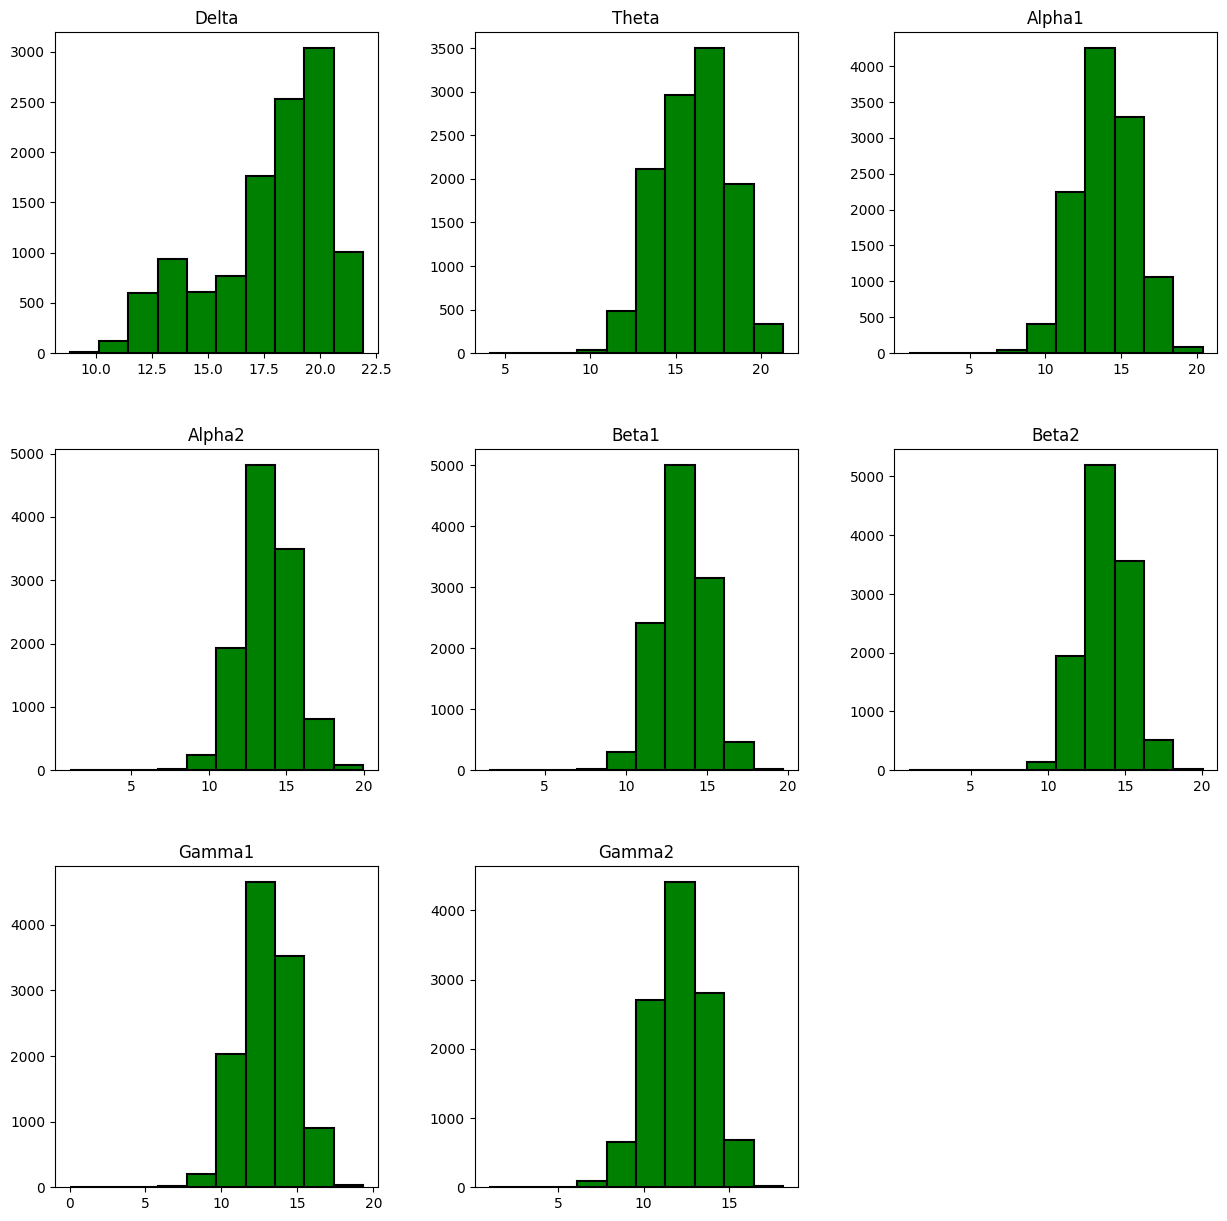

In [32]:
#Applying non-linear normalization for spreading the data
X_n = dataset.iloc[:,:-1].copy() #data that will be normalized
X_n.iloc[:,3:11] = np.log2(X_n.iloc[:,3:11] + 0.0001) #spreading the amount data using log normalization technique
X_n.iloc[:,3:11].hist(figsize = (15,15), grid = False, color = "green", edgecolor = 'black',linewidth = 1.5 )

In [ ]:
m = np.mean(X_n, axis=0) # array([16.25, 26.25])
std = np.std(X_n, axis=0) # array([17.45530005, 22.18529919])
md = np.median(X_n,axis = 0)
p75 = np.percentile(X_n,75,axis = 0)
p25 = np.percentile(X_n,25,axis = 0)

In [ ]:
X_n = np.tanh((X_n - md) / (p75 - p25)) #normalization and feature scaling for train set

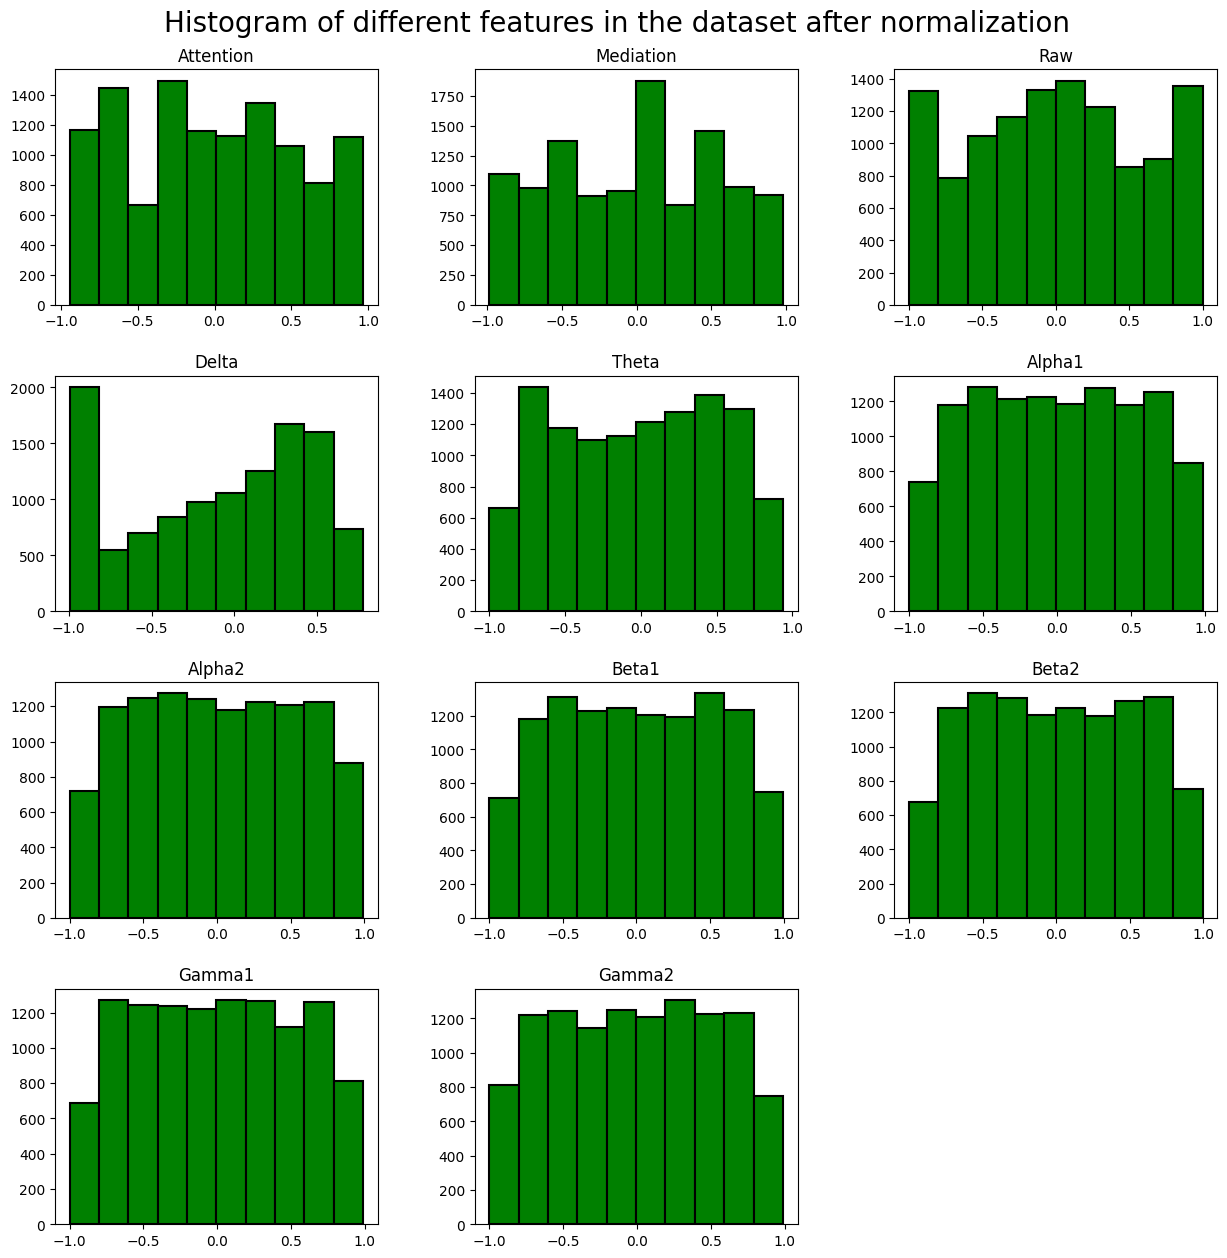

In [ ]:
X_n.hist(figsize = (15,15), grid = False, color = "green", edgecolor = 'black',linewidth = 1.5 )
plt.suptitle('Histogram of different features in the dataset after normalization',fontsize = 20,y= 0.92)
plt.show()

<Axes: >

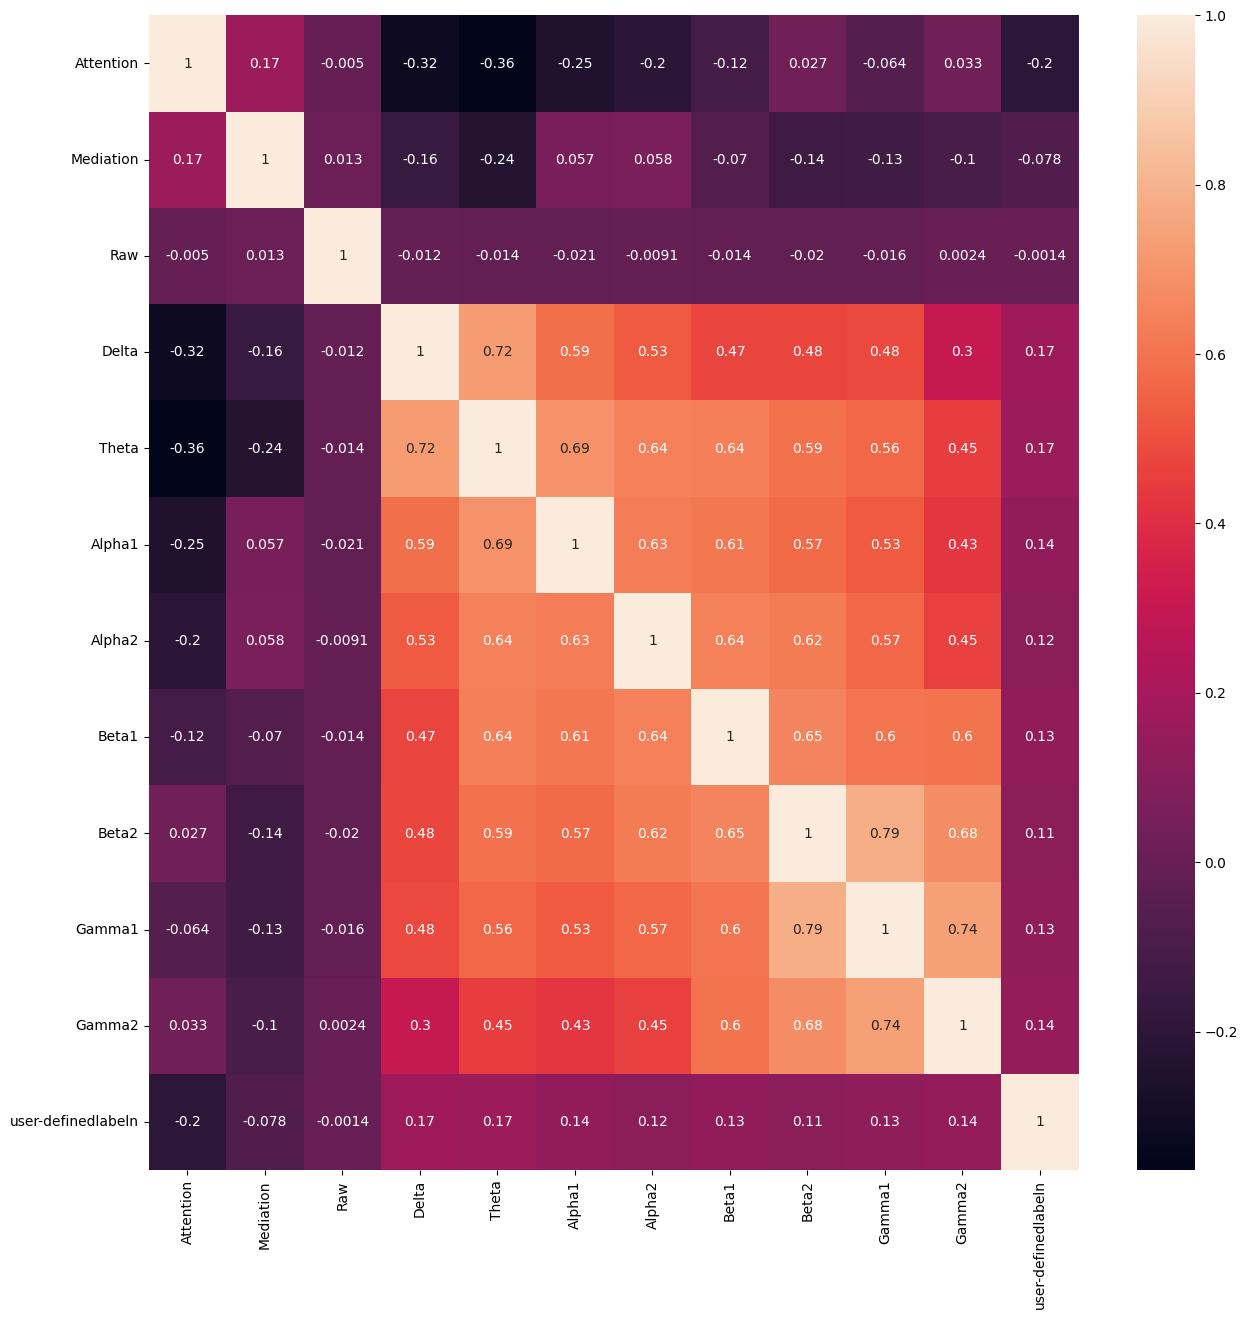

In [ ]:
plt.figure(figsize = (15,15))
cor_matrix = pd.concat((X_n,dataset_all['user-definedlabeln']),axis = 1).corr()
sns.heatmap(cor_matrix,annot=True)

In [ ]:
X = X_n #features
Y = dataset.iloc[:,-1] #targets

In [ ]:
#identify the minimum and maximum length of time-series data in the dataset
VideoID = list(set(data.iloc[:,1]))
SubjectID = list(set(data.iloc[:,0]))
Amin=150 # length of signal
Amax = 0
for i in range(len(SubjectID)):
    for j in range(len(VideoID)):
        Xtemp=data[(data.iloc[:,0]==SubjectID[i]) & (data.iloc[:,1]==VideoID[j])]
        Amin = min(len(Xtemp.iloc[:,14]),Amin)
        Amax = max(len(Xtemp.iloc[:,14]),Amax)
print("The minimum length of the time series data is {}.".format(Amin))
print("The maximum length of the time series data is {}.".format(Amax))

The minimum length of the time series data is 112.
The maximum length of the time series data is 144.


In [ ]:
X = np.asarray(X)
Y = np.asarray(Y)
S = np.asarray(dataset_all.iloc[:,0])
V = np.asarray(dataset_all.iloc[:,1])
X1 = {}
Y1 = {}
for i in range(X.shape[0]): #for each row of features
    s = int(S[i]*10 + V[i])
    if s not in X1.keys():
        X1[s] = X[i]
    elif X1[s].shape[0]<Amin*11: # 112*11
        X1[s] = np.concatenate((X1[s],X[i]),axis =0)
    Y1[s]= Y[i]

In [ ]:
length_dict = {key: len(value) for key, value in X1.items()}
len(set(length_dict.values())) <= 1 #all values are equal

True

In [ ]:
X2 = {}
Y2 = {}
for i in range(X.shape[0]): #for each row of features
    s = int(S[i]*10 + V[i])
    if s not in X2.keys():
        X2[s] = X[i]
    else:
        X2[s] = np.concatenate((X2[s],X[i]),axis =0)
    Y2[s]= Y[i]

for key in X2.keys():
    z = np.zeros(Amax*11 - len(X2[key])) #144X11
    X2[key] = np.concatenate((X2[key],z),axis = 0) #zero padding at the end

In [ ]:
length_dict = {key: len(value) for key, value in X2.items()}
len(set(length_dict.values())) <= 1 #all values are equal

True

In [ ]:
D1 = np.zeros((100,Amin*11),dtype = float)
T = np.zeros((100,1),dtype = int)
D2 = np.zeros((100,Amax*11),dtype = float)
for i in X1.keys():
    D1[i,:] = X1[i]
    D2[i,:] = X2[i]
    T[i] = Y1[i]

In [ ]:
D1 = D1.reshape(-1,1,Amin,11,1)
D2 = D2.reshape(-1,1,Amax,11,1)

In [ ]:
def plotLearningCurve(history,epochs,text):
  epochRange = range(1,epochs+1)
  plt.figure(figsize = (5,5))
  plt.plot(epochRange,history.history['accuracy'])
  plt.plot(epochRange,history.history['val_accuracy'])
  plt.title('Model Accuracy for ' + text)
  plt.xlabel('Epoch', fontsize = 20)
  plt.ylabel('Accuracy', fontsize = 20)
  plt.legend(['Training set','Validation set'])
  plt.show()

  plt.figure(figsize = (5,5))
  plt.plot(epochRange,history.history['loss'])
  plt.plot(epochRange,history.history['val_loss'])
  plt.title('Model Loss for ' + text)
  plt.xlabel('Epoch', fontsize = 20)
  plt.ylabel('Loss', fontsize = 20)
  plt.legend(['Training set','Validation set'])
  plt.show()

In [33]:
def lstm_model(Xtrain,Xtest,ytrain,ytest,maxlen,featlen,epochs):
    i = Input(shape=(None,maxlen,featlen,1)) #maxlen gives us the number of temporal slices per data point
    x = TimeDistributed(Conv2D(16,(3,3),activation = 'tanh'))(i)
    x = Dropout(0.05)(x)
    x = TimeDistributed(Conv2D(32,(5,5),activation = 'tanh'))(x)
    x = Dropout(0.05)(x)
    x = TimeDistributed(MaxPooling2D(pool_size=(2, 2)))(x)
    x = TimeDistributed(Flatten())(x)
    x = Bidirectional(LSTM(75, return_sequences=True),merge_mode = 'ave')(x)
    x = Dense(1, activation='sigmoid')(x)
    model = Model(i, x)
    model.summary()
    #Training the LSTM
    model.compile(optimizer='adam',
              loss='binary_crossentropy',
              metrics=['accuracy'])
    r = model.fit(Xtrain,ytrain,
                  validation_data = (Xtest,ytest),
                  epochs = epochs,
                  verbose = 2,
                  batch_size = 32,
                 shuffle = True)
    print("Train score:", model.evaluate(Xtrain,ytrain))
    print("Test score:", model.evaluate(Xtest,ytest))
    return r,model

In [ ]:
#For dataset D1
Xtrain, Xtest, ytrain, ytest = train_test_split(D1, T, test_size=0.2, random_state=0)
r,model = lstm_model(Xtrain,Xtest,ytrain,ytest,Amin,11,epochs = 100)

Model: "model"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_1 (InputLayer)        [(None, None, 112, 11,    0         
                             1)]                                 
                                                                 
 time_distributed (TimeDist  (None, None, 110, 9, 16   160       
 ributed)                    )                                   
                                                                 
 dropout (Dropout)           (None, None, 110, 9, 16   0         
                             )                                   
                                                                 
 time_distributed_1 (TimeDi  (None, None, 106, 5, 32   12832     
 stributed)                  )                                   
                                                                 
 dropout_1 (Dropout)         (None, None, 106, 5, 32   0     

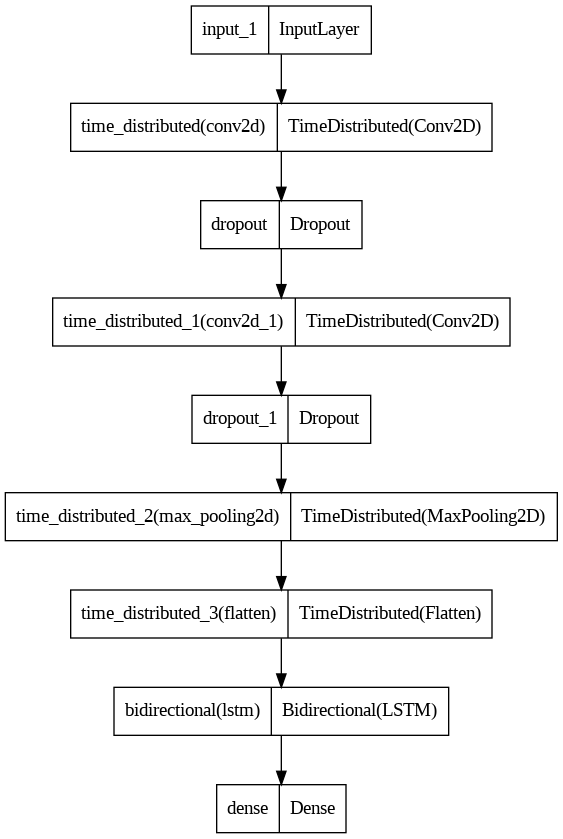

In [ ]:
plot_model(model)

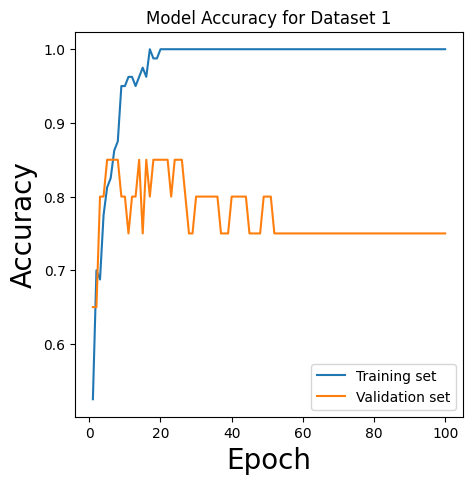

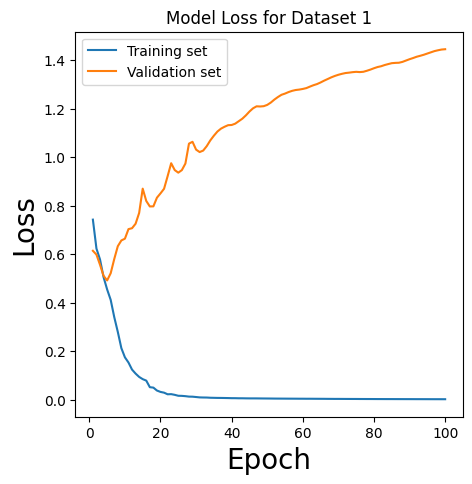

In [ ]:
 plotLearningCurve(r,100,text = 'Dataset 1')

1/1 [==============================] - 2s 2s/step


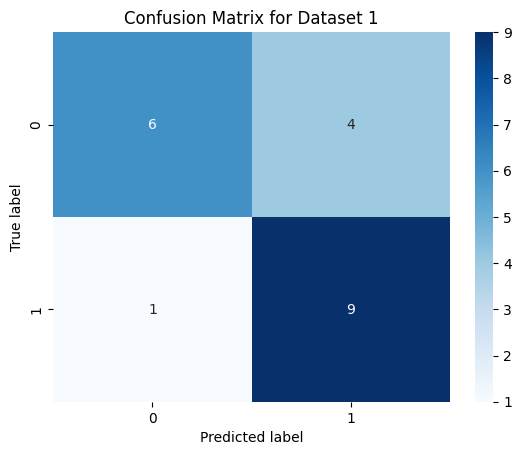

In [ ]:
#Generate predictions for the test dataset
ypred = model.predict(Xtest,batch_size = 32).flatten()
ypred = ypred>0.5
#Get the confusion matrix
cf_matrix = confusion_matrix(ytest, ypred)
sns.heatmap(cf_matrix,annot = True,fmt ='g', cmap='Blues')
plt.xlabel('Predicted label')
plt.ylabel('True label')
plt.title('Confusion Matrix for Dataset 1')
plt.show()

In [ ]:
#For dataset D2
Xtrain, Xtest, ytrain, ytest = train_test_split(D2, T, test_size=0.2,random_state = 0)
r,model = lstm_model(Xtrain,Xtest,ytrain,ytest,Amax,11,epochs = 100)

Model: "model_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_2 (InputLayer)        [(None, None, 144, 11,    0         
                             1)]                                 
                                                                 
 time_distributed_4 (TimeDi  (None, None, 142, 9, 16   160       
 stributed)                  )                                   
                                                                 
 dropout_2 (Dropout)         (None, None, 142, 9, 16   0         
                             )                                   
                                                                 
 time_distributed_5 (TimeDi  (None, None, 138, 5, 32   12832     
 stributed)                  )                                   
                                                                 
 dropout_3 (Dropout)         (None, None, 138, 5, 32   0   

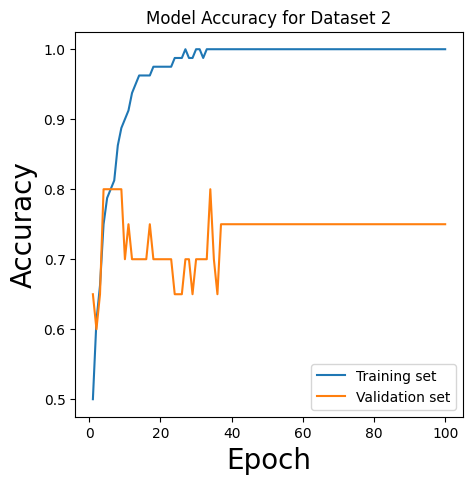

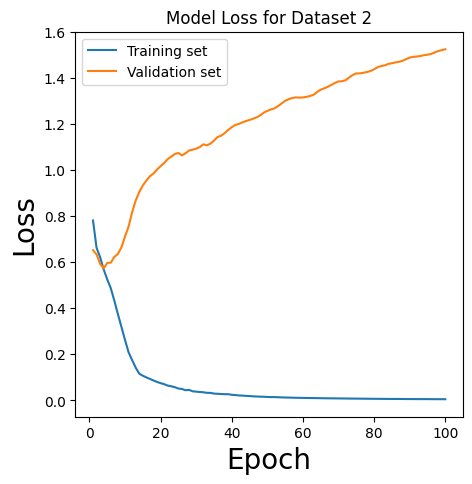

In [ ]:
plotLearningCurve(r,100,text = 'Dataset 2')

1/1 [==============================] - 2s 2s/step


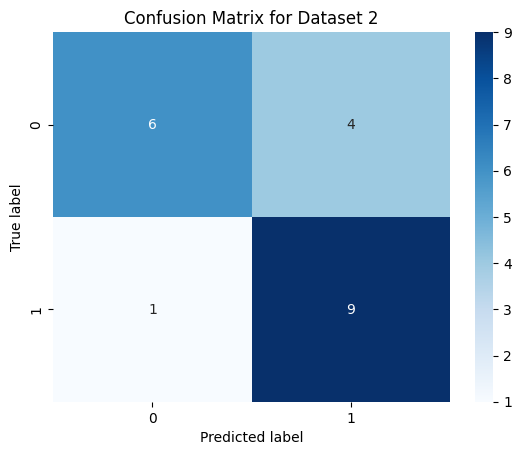

In [ ]:
#Generate predictions for the test dataset
ypred = model.predict(Xtest,batch_size = 32).flatten()
ypred = ypred>0.5
#Get the confusion matrix
cf_matrix = confusion_matrix(ytest, ypred)
sns.heatmap(cf_matrix,annot = True,fmt ='g', cmap='Blues')
plt.xlabel('Predicted label')
plt.ylabel('True label')
plt.title('Confusion Matrix for Dataset 2')
plt.show()